# 01 · Exploratory Data Analysis — Singapore HDB Rent

This notebook examines the structure, quality, rental distributions, temporal trends, and auxiliary-data matching coverage of the eight supplied CSV files.
**It does not delete raw records or fit predictive models.** The test set is used only to inspect input formats, date ranges, and coverage; it does not contain ground-truth rents.

Before running: Place `train.csv`, `test.csv`, and the six `sg-*.csv` files in the project's `data/raw/` directory. The auxiliary tables may also be placed in `data/raw/auxiliary-data/`. Select the `Python (HDBRent)` kernel and choose Run All.


In [13]:
from pathlib import Path
import os
import json
import re
import hashlib
import platform
import importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

def locate_project_root():
    override = os.environ.get('HDB_PROJECT_ROOT')
    candidates = [Path(override).expanduser().resolve()] if override else [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / 'data' / 'raw' / 'train.csv').is_file():
            return candidate
    raise FileNotFoundError('Put train.csv and test.csv in PROJECT/data/raw/. Open this notebook from PROJECT or PROJECT/notebooks/.')

ROOT = locate_project_root()
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
OUTPUTS = ROOT / 'outputs'
for directory in [PROCESSED, OUTPUTS]:
    directory.mkdir(parents=True, exist_ok=True)

FILES = ['train.csv', 'test.csv', 'sg-hdb-block.csv', 'sg-mrt-stations.csv',
         'sg-shopping-malls.csv', 'sg-schools.csv', 'sg-coe-prices.csv', 'sg-stock-prices.csv']

def raw_path(name):
    candidates = [RAW / name, RAW / 'auxiliary-data' / name]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Missing {name}: expected in {RAW} or {RAW / "auxiliary-data"}.')

def load_raw(name):
    # Preserve identifiers such as 090034 and 321A as text.
    return pd.read_csv(raw_path(name), dtype={'BLOCK': 'string', 'POSTAL_CODE': 'string'})

def clean_text(series):
    return series.astype('string').str.normalize('NFKC').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

def canonical_flat_type(series):
    return clean_text(series).str.replace(r'[\s-]*room\b', '-room', regex=True)

def canonical_keys(frame):
    out = frame.copy()
    for column in ['TOWN', 'BLOCK', 'STREET']:
        if column in out:
            out[column] = clean_text(out[column])
    if 'FLAT_TYPE' in out:
        out['FLAT_TYPE'] = canonical_flat_type(out['FLAT_TYPE'])
    return out

def parse_amount(series):
    return pd.to_numeric(series.astype('string').str.replace(r'[$,\s]', '', regex=True), errors='coerce')

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def parse_coe_date(year, month):
    month_map = {
        'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4,
        'may': 5, 'jun': 6, 'jul': 7, 'aug': 8,
        'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
    }

    month_number = (
        month.astype('string')
        .str.strip()
        .str.lower()
        .map(month_map)
    )

    if month_number.isna().any():
        invalid_values = month.loc[month_number.isna()].unique()
        raise ValueError(f'Unrecognized month values: {invalid_values}')

    return pd.to_datetime({
        'year': year,
        'month': month_number,
        'day': 1
    })

print('Project:', ROOT)
print('Python:', platform.python_version())


Project: d:\AppData\NUS\Sem1\5228 Knowledge Discovery and Data Mining\cs5228-hdb-rent-prediction
Python: 3.12.15


## 1. File Overview and Data Contract
Fields are identified from the actual files. `FURNISHED`, `FEE`, and `FLAT_MODEL` are also present in the current data. Run this chunk to actually check if there's something unusual with the raw data.


In [2]:
tables = {name: load_raw(name) for name in FILES}
train = tables['train.csv']
test = tables['test.csv']
assert 'MONTHLY_RENT' in train and 'MONTHLY_RENT' not in test
assert set(train.columns) - {'MONTHLY_RENT'} == set(test.columns)
inventory = pd.DataFrame([{
    'file': name, 'rows': len(frame), 'columns': frame.shape[1],
    'missing_cells': int(frame.isna().sum().sum()), 'exact_duplicate_rows': int(frame.duplicated().sum())
} for name, frame in tables.items()])
display(inventory)
display(train.head())
display(pd.DataFrame({'dtype': train.dtypes.astype(str), 'n_unique': train.nunique(dropna=False),
                      'missing': train.isna().sum()}))


,file,rows,columns,missing_cells,exact_duplicate_rows
0,train.csv,150000,11,0,425
1,test.csv,50000,10,0,5508
2,sg-hdb-block.csv,9464,11,0,0
3,sg-mrt-stations.csv,243,8,0,0
4,sg-shopping-malls.csv,113,3,0,0
5,sg-schools.csv,337,14,0,0
6,sg-coe-prices.csv,539,8,0,0
7,sg-stock-prices.csv,91642,9,510,0


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800


,dtype,n_unique,missing
RENT_APPROVAL_DATE,object,51,0
TOWN,object,26,0
BLOCK,string,2720,0
STREET,object,1146,0
FLAT_TYPE,object,11,0
FLAT_MODEL,object,20,0
FLOOR_AREA_SQM,float64,156,0
FURNISHED,object,1,0
LEASE_COMMENCE_DATE,int64,57,0
FEE,float64,1,0


## 2. Temporal Coverage: The Test Task Requires Substantial Extrapolation into the Future
Records are summarized by calendar month to distinguish future rent prediction from evaluation based on a random split. The two datasets may share a boundary month, but without day-level timestamps, the exact chronological order of records within that month cannot be determined.


,split,rows,first_month,last_month,months
0,train,150000,2021-01,2025-03,51
1,test,50000,2025-03,2026-07,17


,train,test
RENT_APPROVAL_DATE,,
2024-12,2896,0
2025-01,2870,0
2025-02,3022,0
2025-03,3032,380
2025-04,0,3112
2025-05,0,3312
2025-06,0,3296
2025-07,0,3567
2025-08,0,3096


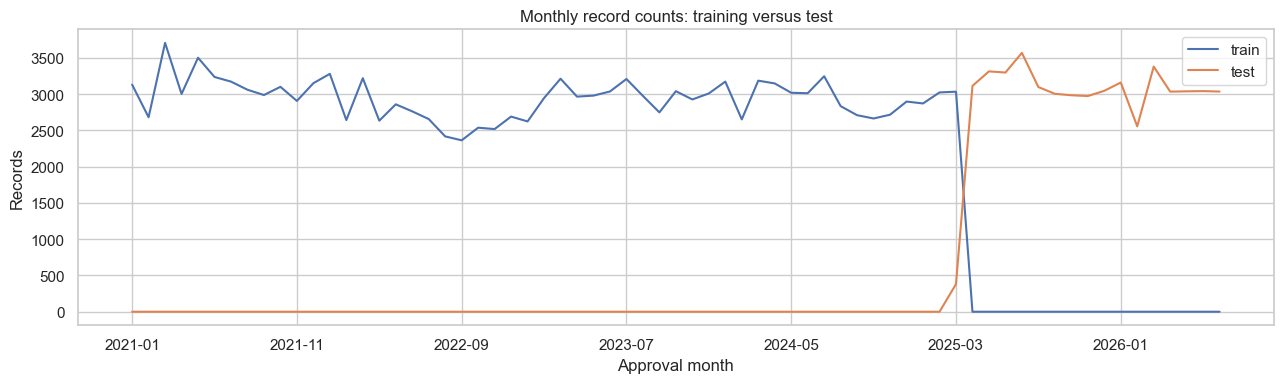

In [3]:
monthly_counts = pd.concat([
    train.groupby('RENT_APPROVAL_DATE').size().rename('train'),
    test.groupby('RENT_APPROVAL_DATE').size().rename('test')
], axis=1).fillna(0).astype(int).sort_index()
date_ranges = pd.DataFrame([
    {'split': name, 'rows': len(frame), 'first_month': frame.RENT_APPROVAL_DATE.min(),
     'last_month': frame.RENT_APPROVAL_DATE.max(), 'months': frame.RENT_APPROVAL_DATE.nunique()}
    for name, frame in [('train', train), ('test', test)]
])
display(date_ranges)
display(monthly_counts.tail(20))
ax = monthly_counts.plot(figsize=(13, 4), title='Monthly record counts: training versus test')
ax.set(xlabel='Approval month', ylabel='Records')
plt.tight_layout(); plt.show()


## 3. Missing Values, Constants, Outliers, and Duplicate Records
The absence of missing values does not eliminate the need for cleaning. Differences in capitalization, whitespace, and category formatting can affect joins and model inputs.

Identical public records are not necessarily errors: without unit identifiers, multiple tenancy agreements may have identical attributes. Therefore, **duplicate records are retained** by default, and their counts are reported separately. High- or low-rent observations are not arbitrarily removed using rent quantiles calculated over the full dataset.


In [4]:
constant_columns = [c for c in train if c != 'MONTHLY_RENT' and train[c].nunique(dropna=False) <= 1]
checks = pd.Series({
    'nonpositive_rent': int((train.MONTHLY_RENT <= 0).sum()),
    'nonpositive_area_train': int((train.FLOOR_AREA_SQM <= 0).sum()),
    'nonpositive_area_test': int((test.FLOOR_AREA_SQM <= 0).sum()),
    'invalid_month_train': int(pd.to_datetime(train.RENT_APPROVAL_DATE, format='%Y-%m', errors='coerce').isna().sum()),
    'lease_year_after_approval_train': int((train.LEASE_COMMENCE_DATE > pd.to_datetime(train.RENT_APPROVAL_DATE).dt.year).sum()),
    'exact_duplicates_train': int(train.duplicated().sum()),
    'identical_predictors_train': int(train.drop(columns='MONTHLY_RENT').duplicated().sum()),
    'identical_predictors_test': int(test.duplicated().sum())
}, name='count')
print('Constant training columns:', constant_columns)
display(checks.to_frame())
missing = pd.DataFrame({name: frame.isna().sum() for name, frame in tables.items()}).fillna(0).astype(int)
display(missing.loc[(missing > 0).any(axis=1)])
display(train.MONTHLY_RENT.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())


Constant training columns: ['FURNISHED', 'FEE']


,count
nonpositive_rent,0
nonpositive_area_train,0
nonpositive_area_test,0
invalid_month_train,0
lease_year_after_approval_train,1
exact_duplicates_train,425
identical_predictors_train,15547
identical_predictors_test,5508


,train.csv,test.csv,sg-hdb-block.csv,sg-mrt-stations.csv,sg-shopping-malls.csv,sg-schools.csv,sg-coe-prices.csv,sg-stock-prices.csv
ADJUSTED_CLOSE,0,0,0,0,0,0,0,85
CLOSE,0,0,0,0,0,0,0,85
HIGH,0,0,0,0,0,0,0,85
LOW,0,0,0,0,0,0,0,85
OPEN,0,0,0,0,0,0,0,85
VOLUME,0,0,0,0,0,0,0,85


,MONTHLY_RENT
count,150000.000000
mean,2719.036893
std,749.731096
min,300.000000
1%,1300.000000
5%,1650.000000
50%,2700.000000
95%,4000.000000
99%,4600.000000
max,7600.000000


## 4. Categorical Cleaning: Standardizing Flat Types, Addresses, and Capitalization
`4 room` and `4-room` should represent the same flat type. Only interpretable formatting normalization is applied here; rental values are not used, and fuzzy address matching is not performed.


In [5]:
clean_train = canonical_keys(train)
clean_test = canonical_keys(test)
flat_mapping = train[['FLAT_TYPE']].drop_duplicates().copy()
flat_mapping['canonical'] = canonical_flat_type(flat_mapping.FLAT_TYPE)
display(flat_mapping.sort_values('canonical').reset_index(drop=True))
display(pd.crosstab(clean_train.FLAT_TYPE, columns='count').sort_index())
address_changes = pd.DataFrame([
    {'split': name, 'column': column, 'changed_rows': int((raw[column].astype('string') != cleaned[column]).sum())}
    for name, raw, cleaned in [('train', train, clean_train), ('test', test, clean_test)]
    for column in ['TOWN', 'BLOCK', 'STREET']
])
display(address_changes)


,FLAT_TYPE,canonical
0,1 room,1-room
1,1-room,1-room
2,2 room,2-room
3,2-room,2-room
4,3 room,3-room
5,3-room,3-room
6,4 room,4-room
7,4-room,4-room
8,5 room,5-room
9,5-room,5-room


col_0,count
FLAT_TYPE,
1-room,42
2-room,3098
3-room,49024
4-room,54079
5-room,35523
executive,8234


,split,column,changed_rows
0,train,TOWN,0
1,train,BLOCK,0
2,train,STREET,30781
3,test,TOWN,0
4,test,BLOCK,0
5,test,STREET,10482


## 5. Rental Distributions and Property Attributes
The rent per m² shown in the plots is used only to interpret the training data. **It is not used as a predictive feature**, because it contains the target rental value.


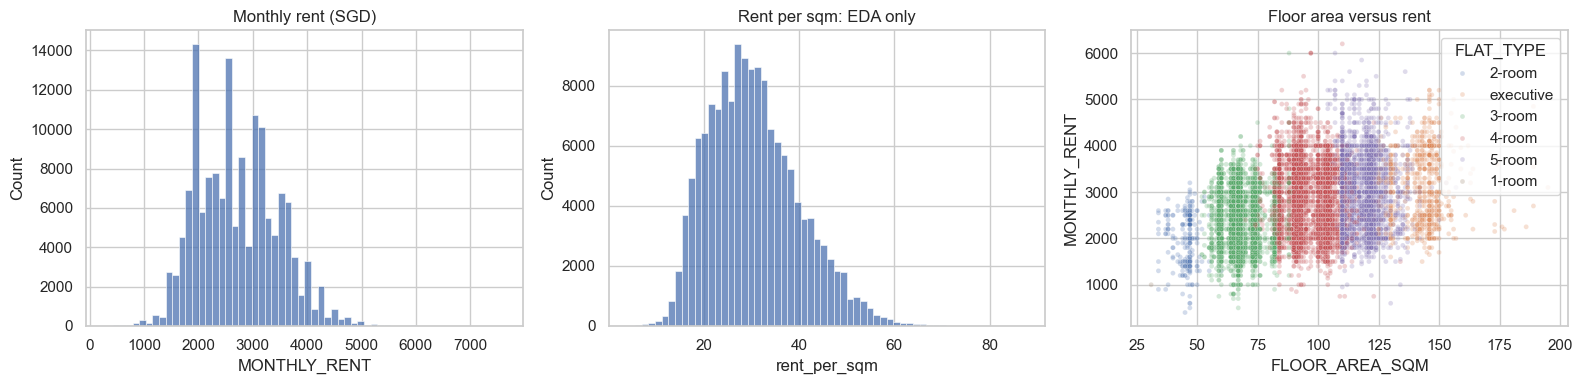

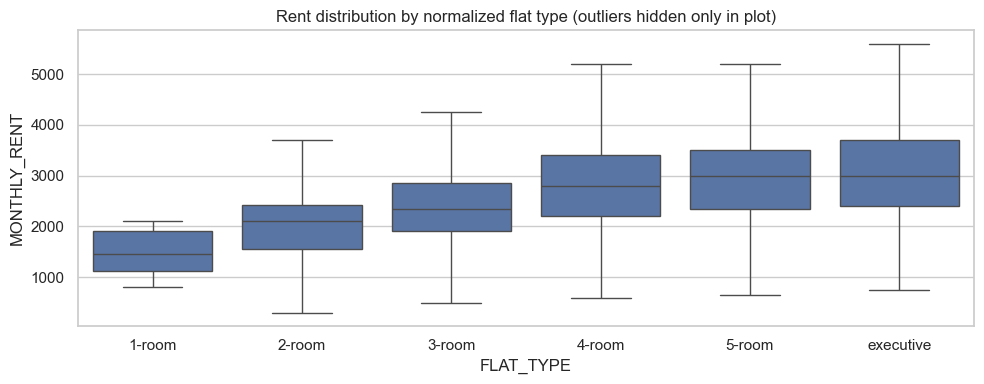

In [6]:
plot_data = clean_train.copy()
plot_data['rent_per_sqm'] = plot_data.MONTHLY_RENT / plot_data.FLOOR_AREA_SQM
sample = plot_data.sample(min(12000, len(plot_data)), random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(plot_data.MONTHLY_RENT, bins=60, ax=axes[0]); axes[0].set_title('Monthly rent (SGD)')
sns.histplot(plot_data.rent_per_sqm, bins=60, ax=axes[1]); axes[1].set_title('Rent per sqm: EDA only')
sns.scatterplot(data=sample, x='FLOOR_AREA_SQM', y='MONTHLY_RENT', hue='FLAT_TYPE',
                alpha=.25, s=12, ax=axes[2]); axes[2].set_title('Floor area versus rent')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=plot_data, x='FLAT_TYPE', y='MONTHLY_RENT', order=sorted(plot_data.FLAT_TYPE.unique()),
            showfliers=False, ax=ax)
ax.set_title('Rent distribution by normalized flat type (outliers hidden only in plot)')
plt.tight_layout(); plt.show()


## 6. Geographic and Temporal Variation

The geographic differences below also reflect differences in flat types, floor areas, time periods, and other characteristics. They should not be interpreted as purely causal location premiums.


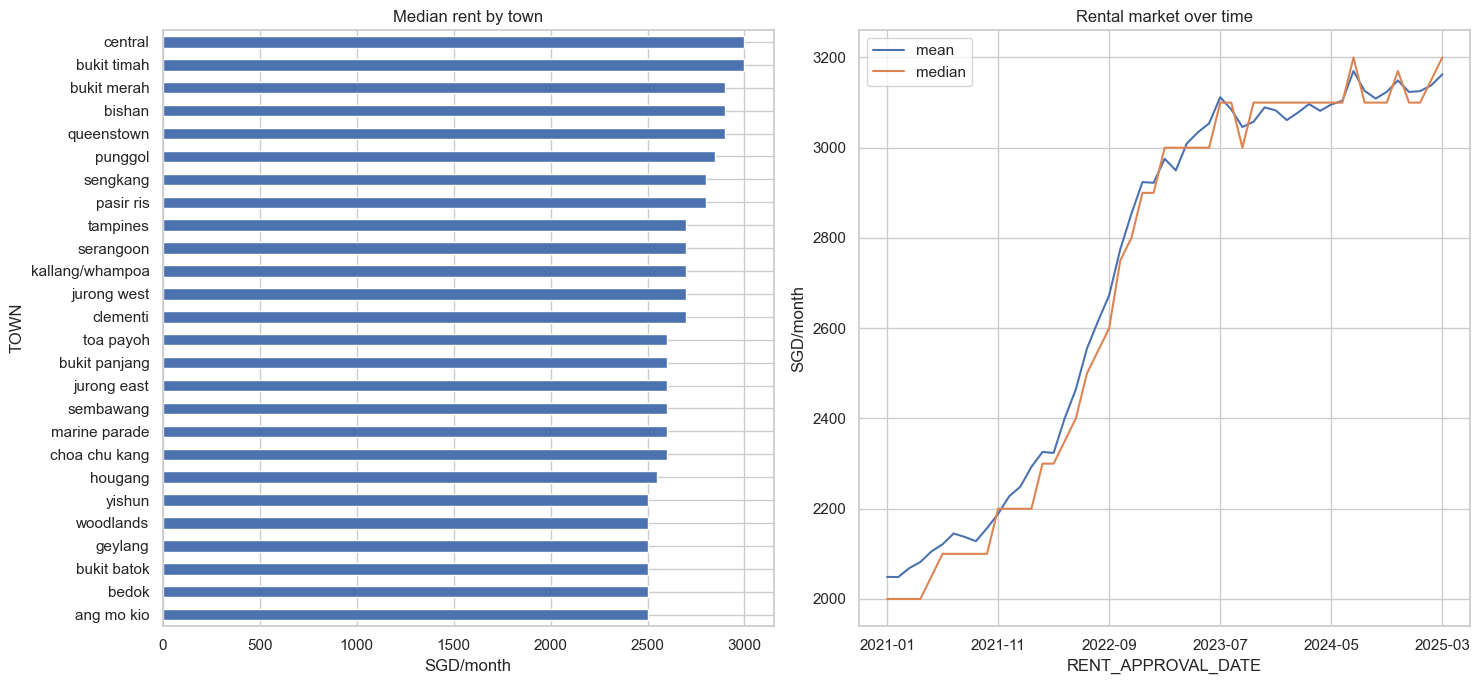

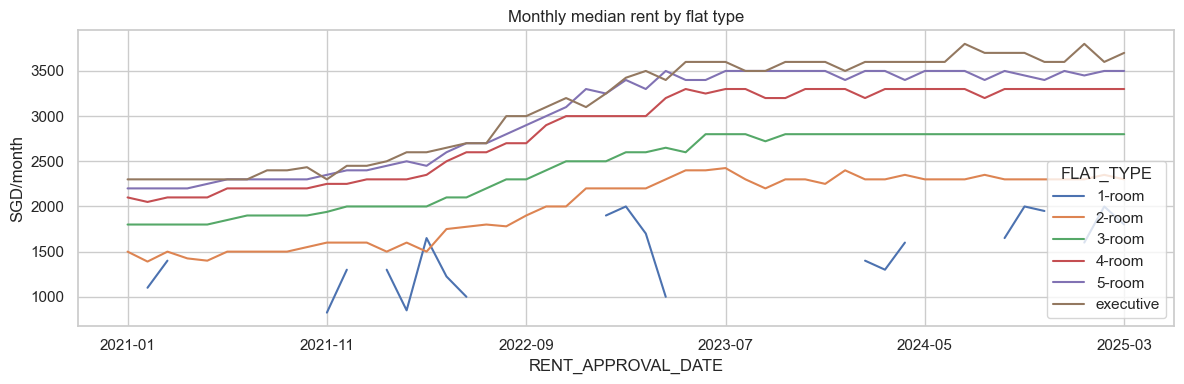

,records,mean_rent,median_rent,mean_area
TOWN,,,,
ang mo kio,8283,2528.25,2500.0,80.89
bedok,8907,2564.58,2500.0,86.00
bukit batok,5605,2579.20,2500.0,89.49
geylang,4504,2595.00,2500.0,79.07
woodlands,7577,2584.88,2500.0,105.11
yishun,7913,2515.43,2500.0,91.32
hougang,7115,2621.42,2550.0,96.86
choa chu kang,5300,2646.13,2600.0,110.52
marine parade,1637,2690.83,2600.0,79.14


In [7]:
town_summary = clean_train.groupby('TOWN').agg(records=('MONTHLY_RENT', 'size'),
    mean_rent=('MONTHLY_RENT', 'mean'), median_rent=('MONTHLY_RENT', 'median'),
    mean_area=('FLOOR_AREA_SQM', 'mean')).sort_values('median_rent')
monthly_rent = clean_train.groupby('RENT_APPROVAL_DATE').MONTHLY_RENT.agg(['mean', 'median', 'count'])
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
town_summary.median_rent.plot.barh(ax=axes[0], title='Median rent by town')
monthly_rent[['mean', 'median']].plot(ax=axes[1], title='Rental market over time')
axes[0].set_xlabel('SGD/month'); axes[1].set_ylabel('SGD/month')
plt.tight_layout(); plt.show()
monthly_by_type = clean_train.groupby(['RENT_APPROVAL_DATE', 'FLAT_TYPE']).MONTHLY_RENT.median().unstack()
monthly_by_type.plot(figsize=(12, 4), title='Monthly median rent by flat type')
plt.ylabel('SGD/month'); plt.tight_layout(); plt.show()
display(town_summary.round(2))


## 7. Input Distributions and Unseen Categories

Test inputs may be used to detect schema and coverage issues, but they are not used to fit imputers, scalers, or categorical encoders. Numerical distribution drift is examined for diagnostic purposes only; test labels are not used for hyperparameter tuning.


In [8]:
category_drift = []
for column in ['TOWN', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']:
    a = clean_text(clean_train[column]); b = clean_text(clean_test[column])
    unseen = ~b.isin(set(a.dropna()))
    category_drift.append({'column': column, 'train_categories': a.nunique(), 'test_categories': b.nunique(),
                           'unseen_test_rows': int(unseen.sum()), 'unseen_test_rate': float(unseen.mean())})
display(pd.DataFrame(category_drift))
numeric_drift = []
for column in ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE']:
    a = train[column]; b = test[column]
    numeric_drift.append({'column': column, 'train_mean': a.mean(), 'test_mean': b.mean(),
        'train_median': a.median(), 'test_median': b.median(),
        'mean_shift_in_train_sd': (b.mean() - a.mean()) / a.std()})
display(pd.DataFrame(numeric_drift).round(3))


,column,train_categories,test_categories,unseen_test_rows,unseen_test_rate
0,TOWN,26,26,0,0.0
1,STREET,576,573,0,0.0
2,FLAT_TYPE,6,6,0,0.0
3,FLAT_MODEL,20,19,0,0.0


,column,train_mean,test_mean,train_median,test_median,mean_shift_in_train_sd
0,FLOOR_AREA_SQM,93.339,92.484,92.0,92.0,-0.035
1,LEASE_COMMENCE_DATE,1990.907,1991.690,1988.0,1988.0,0.062


## 8. Building Matching: Town + Block + Street

Block alone is insufficient because the same block number may occur on different streets. The normalized three-column composite key should be unique in the auxiliary table. `validate='many_to_one'` is used to prevent incorrect many-to-many joins.


,split,rows,matched,coverage
0,train,150000,150000,1.0
1,test,50000,50000,1.0


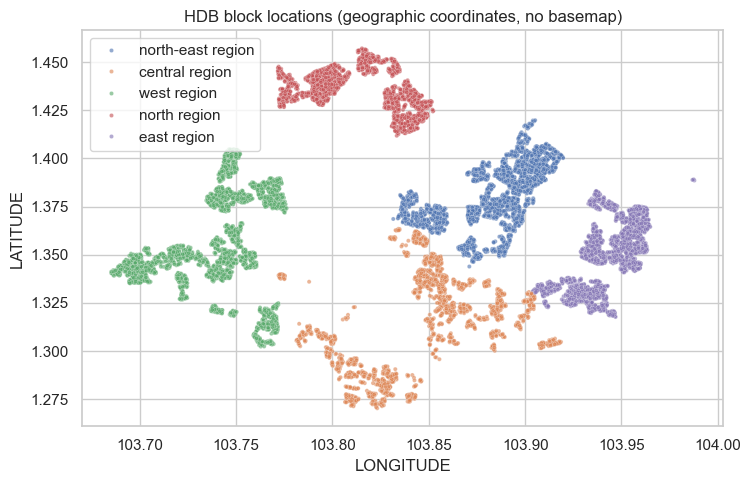

In [10]:
blocks = canonical_keys(tables['sg-hdb-block.csv'])
keys = ['TOWN', 'BLOCK', 'STREET']
assert not blocks.duplicated(keys).any(), 'Duplicate block keys need explicit resolution.'
join_audit = []
for name, frame in [('train', clean_train), ('test', clean_test)]:
    merged = frame.merge(blocks, on=keys, how='left', validate='many_to_one', indicator=True)
    assert len(merged) == len(frame)
    join_audit.append({'split': name, 'rows': len(frame), 'matched': int(merged._merge.eq('both').sum()),
                       'coverage': float(merged._merge.eq('both').mean())})
display(pd.DataFrame(join_audit))
geo = blocks.dropna(subset=['LATITUDE', 'LONGITUDE'])
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=geo, x='LONGITUDE', y='LATITUDE', hue='REGION', s=9, alpha=.6, ax=ax)
ax.legend(loc='upper left')
ax.set_title('HDB block locations (geographic coordinates, no basemap)')
ax.set_aspect(1 / np.cos(np.radians(geo.LATITUDE.mean())))
plt.tight_layout(); plt.show()


## 9. Landmark Coverage and Historical Information Limitations

The open/planned status of MRT stations is a snapshot from the supplied file; **historical opening dates are unavailable**. Interchange stations with the same name should be counted as a single location.

The school table contains more than primary schools. Feature engineering will select primary schools and mixed-level schools that include p1. Historical opening dates are also unavailable for malls and schools.


In [11]:
mrt = tables['sg-mrt-stations.csv']
schools = tables['sg-schools.csv']
display(mrt.STATUS.value_counts().rename_axis('mrt_status').to_frame('rows'))
display(schools.MAINLEVEL_CODE.value_counts().rename_axis('school_level').to_frame('rows'))
poi_audit = pd.DataFrame([
    {'source': 'mrt', 'rows': len(mrt), 'unique_names': clean_text(mrt.NAME).nunique()},
    {'source': 'malls', 'rows': len(tables['sg-shopping-malls.csv']),
     'unique_names': clean_text(tables['sg-shopping-malls.csv'].NAME).nunique()},
    {'source': 'schools', 'rows': len(schools), 'unique_names': clean_text(schools.NAME).nunique()}
])
display(poi_audit)


,rows
mrt_status,
open,231
planned,12


,rows
school_level,
primary,179
secondary (s1-s5),117
secondary (s1-s4),16
junior college,10
mixed level (s1-jc2),10
mixed level (p1-s4),3
centralised institute,1
"mixed level (s1-s5, jc1-jc2)",1


,source,rows,unique_names
0,mrt,243,192
1,malls,113,113
2,schools,337,337


## 10. Macroeconomic Data: Formats, Coverage, and Temporal Alignment

COE values contain `$` symbols and thousands separators. Stock data are recorded daily and contain missing rows. Stock prices denominated in different currencies are not directly averaged.

Subsequent processing uses only a predefined selection of `.SI` stocks as proxies, constructing month-end CLOSE values and historical returns separately for each stock. ADJUSTED_CLOSE is not used because it may be affected by retrospective dividend adjustments.


,first_date,last_date,rows,valid_close
SYMBOL,,,,
SWICH.AS,2026-02-19,2026-07-30,113,113
SMJF,2025-12-04,2026-07-30,163,163
POAS,2025-11-13,2026-07-30,177,177
BGIN,2025-10-21,2026-07-30,194,194
EGG,2025-06-18,2026-07-30,280,280
ANTA,2025-05-13,2026-07-30,305,305
BLIV,2025-04-04,2026-07-30,331,331
ORKT,2024-07-25,2026-07-30,505,505
MNDR,2024-04-10,2026-07-30,578,578


Stock symbols: 77 | Missing CLOSE rows: 85


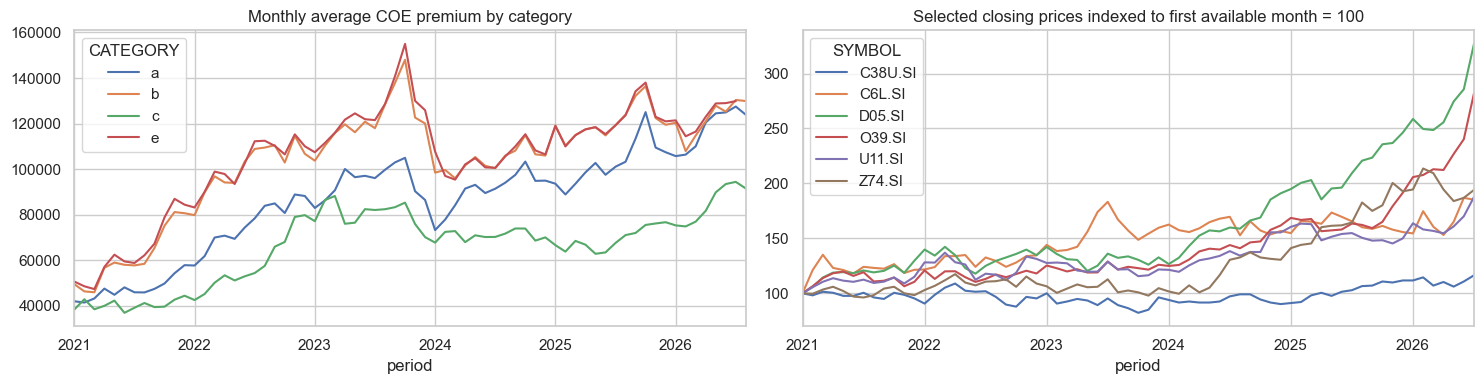

In [14]:
coe = tables['sg-coe-prices.csv'].copy()
coe['premium_numeric'] = parse_amount(coe.QUOTA_PREMIUM)
coe['period'] = parse_coe_date(coe['YEAR'], coe['MONTH']).dt.to_period('M')
coe_monthly = coe.pivot_table(index='period', columns='CATEGORY', values='premium_numeric', aggfunc='mean')
stocks = tables['sg-stock-prices.csv'].copy()
stocks['DATE'] = pd.to_datetime(stocks.DATE)
stock_coverage = stocks.groupby('SYMBOL').agg(first_date=('DATE', 'min'), last_date=('DATE', 'max'),
    rows=('DATE', 'size'), valid_close=('CLOSE', 'count'))
display(stock_coverage.sort_values('rows').head(12))
print('Stock symbols:', stocks.SYMBOL.nunique(), '| Missing CLOSE rows:', stocks.CLOSE.isna().sum())
selected_symbols = ['D05.SI', 'O39.SI', 'U11.SI', 'C6L.SI', 'Z74.SI', 'C38U.SI']
stock_view = stocks[stocks.SYMBOL.isin(selected_symbols)].copy()
stock_view['period'] = stock_view.DATE.dt.to_period('M')
month_close = stock_view.sort_values('DATE').groupby(['period', 'SYMBOL']).CLOSE.last().unstack()
normalized = month_close.div(month_close.apply(lambda s: s.dropna().iloc[0]), axis=1) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
coe_monthly.plot(ax=axes[0], title='Monthly average COE premium by category')
normalized.plot(ax=axes[1], title='Selected closing prices indexed to first available month = 100')
plt.tight_layout(); plt.show()


## 11. Pre-modeling Decisions and Exports

- The primary validation uses a temporal split: fit on 2021–2022, select models using 2023, and reserve 2024–2025-03 as an independent temporal holdout.
- The holdout spans approximately 15 months, making it closer to the challenge of predicting rents across multiple future months in the test set. Market changes in 2023 also mean that the validation and final test distributions may differ.
- Constant columns without predictive information are excluded by default, while valid extreme rents and duplicate records are retained.
- Joins and geometric distance calculations do not use labels. Imputation, encoding, and scaling are fitted only within each training fold.
- Monthly macroeconomic features use a fixed forecast origin by default: information available to future rows is frozen at the training-end month. A rolling monthly assumption is also available, but the two settings address different forecasting questions.
- According to the Kaggle evaluation metric, the notebooks select models using RMSE and also report MAE, RMSLE, and R².
- `example-submission.csv` has not been provided. The final training notebook saves row-level predictions; the actual template is required to generate an official submission file.


In [15]:
eda_dir = OUTPUTS / 'eda'
eda_dir.mkdir(parents=True, exist_ok=True)
inventory.to_csv(eda_dir / 'file_inventory.csv', index=False)
date_ranges.to_csv(eda_dir / 'date_ranges.csv', index=False)
monthly_counts.to_csv(eda_dir / 'monthly_counts.csv')
monthly_rent.to_csv(eda_dir / 'monthly_rent_summary.csv')
town_summary.to_csv(eda_dir / 'town_summary.csv')
pd.DataFrame(join_audit).to_csv(eda_dir / 'block_join_audit.csv', index=False)
summary = {'train_rows': len(train), 'test_rows': len(test), 'constant_columns': constant_columns,
           'train_first_month': train.RENT_APPROVAL_DATE.min(), 'train_last_month': train.RENT_APPROVAL_DATE.max(),
           'test_first_month': test.RENT_APPROVAL_DATE.min(), 'test_last_month': test.RENT_APPROVAL_DATE.max(),
           'checks': {k: int(v) for k, v in checks.items()}, 'duplicate_policy': 'retain'}
(eda_dir / 'eda_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('EDA summaries saved to:', eda_dir)


EDA summaries saved to: d:\AppData\NUS\Sem1\5228 Knowledge Discovery and Data Mining\cs5228-hdb-rent-prediction\outputs\eda
